# Evaluate a single EpiHydra clock

Loads the EpiHydra model (LoRA-adapted MethylGPT backbone + AgePredictor head), selects one clock head, and reports MAE / R² / Pearson r with a predicted-vs-target scatter plot.

- `CLOCK = "age"` (default) uses the head already stored in `best_model.pt`, so no head swapping is needed.
- Any other clock (e.g. `"phenoage_age"`) swaps in `best_head_<CLOCK>.pt` from `HEAD_PATH`.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path

# ── Which clock to evaluate ──────────────────────────────────────
CLOCK      = "age"     # "age" (default) or a clock head name, e.g. "phenoage_age"

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined_test/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks3_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261114_202909"

SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
MASK_WEIGHTS = dict(uniform=0.0, low_variance=0.0, high_variance=0.0)
BATCH_SIZE   = 16
RANDOM_STATE = 42

## Imports

In [2]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_dataloaders, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Evaluating clock: '{CLOCK}'")

Using device: cuda
Evaluating clock: 'age'


## Load data, config and vocab

In [11]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

# MethylGPT pre-training config (layer sizes, number of CpGs, ...)
with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

# CpG vocabulary used for tokenisation
vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Clock heads reuse the scaler they were trained with. For `"age"` (or any clock without a saved scaler) `build_dataloaders` fits a new one on the training split.

In [12]:
scaler = eu.load_scalers(HEAD_PATH, EPIHYDRA_PATH, clock=CLOCK)

dataloader = build_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_age    = CLOCK,          # target column in the metadata
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scaler       = scaler,
    mask_ratio   = 0.0,
    mask_weights = None,
    **SPLIT_RATIOS,
)

Samples in meta : 1239
Samples in CpG  : 1239
Common samples  : 1239
Samples after NaN drop : 1239

Vocab CpGs : 49,159 | Present : 45,069 (91.7%) | Missing : 4,090
ℹ  Missing CpGs → NaN → padded during tokenisation.
ℹ  Reusing supplied pre-fitted scaler.
✓ Single loader built (1239 samples, no masking).



/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


## Build the model and load weights
The backbone is wrapped with LoRA *before* loading the checkpoint so the parameter names match.

In [13]:
age_model = eu.build_age_model(MODEL_PATH, vocab, pretrain_config, device,
                               ckpt=EPIHYDRA_PATH, head_path=HEAD_PATH, clock=CLOCK)

state = eu.load_clock_state(EPIHYDRA_PATH, HEAD_PATH, clock=CLOCK, device=device)
print(age_model.load_state_dict(state))
age_model.eval();

LoRA from checkpoint: r=16, alpha=32

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")



Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt
trainable params: 258,064 || all params: 15,680,786 || trainable%: 1.6457
<All keys matched successfully>


## Evaluate

In [14]:
_, preds, labels, ids = evaluate(age_model, dataloader['loader'], dataloader['scaler'], device)
metrics = eu.compute_metrics(labels, preds)
eu.print_metrics(metrics)


────────────────────────────────────────
   n        : 1239
   MAE      : 4.67 years
   R²       : 0.867
   Pearson r: 0.939
────────────────────────────────────────



## Predicted vs. target age

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/age_scatter.svg


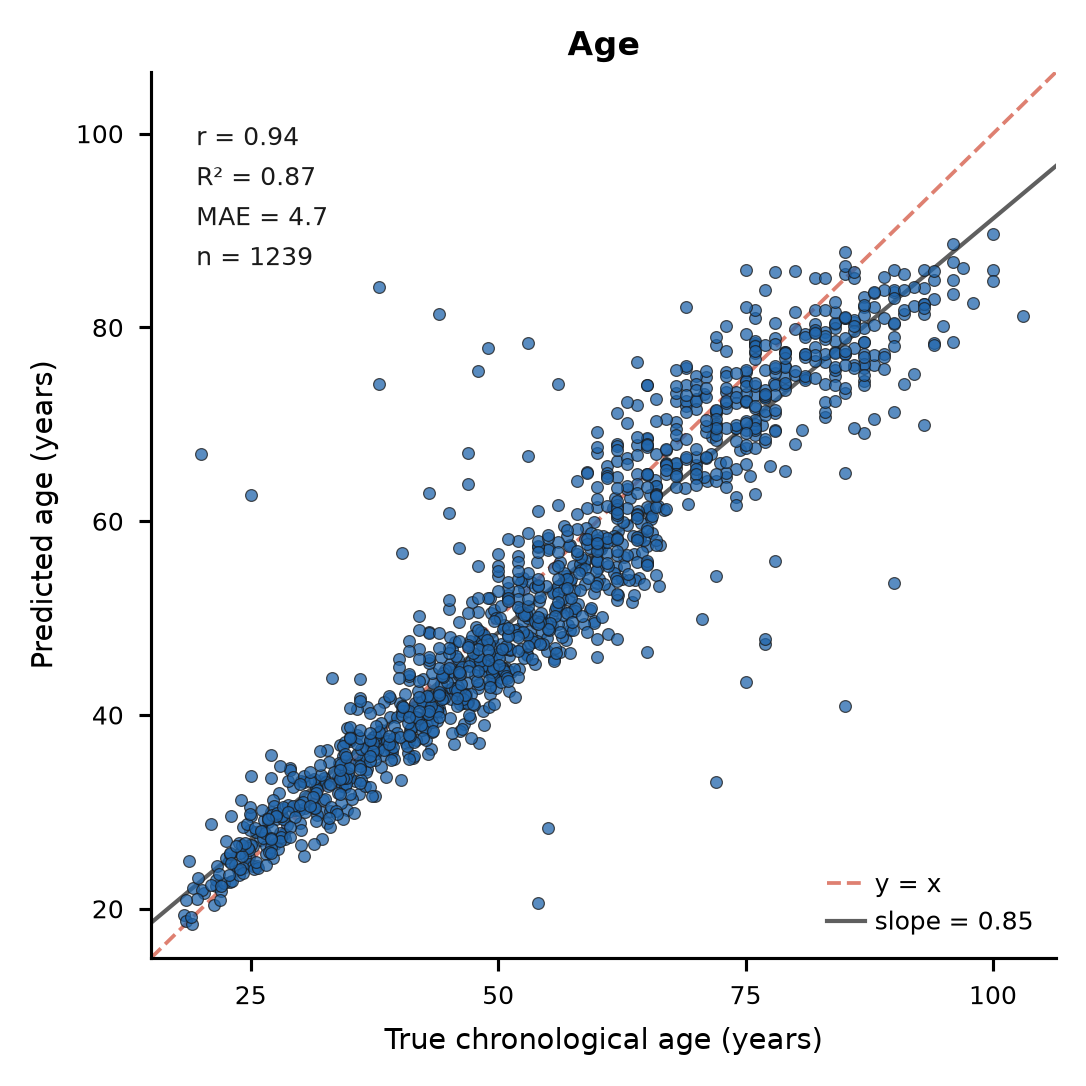

In [22]:
fig = eu.plot_predictions(labels, preds, clock=CLOCK , save_path = '/work/gr-fe/bryan/EpiHydra/results/figures/age_scatter.png')